
# Stardard Multi-Fidelity Bayesian Optimization (MFBO) from Scratch

This notebook is **study-oriented** and aims to be readable for someone with only minimal prior exposure to:
- Bayesian optimization (BO)
- Gaussian processes (GPs)
- multi-fidelity modelling

We focus on the **classical two-fidelity setting with fixed low/high fidelity measurements**:
- **low fidelity** = cheap, biased, less accurate measurement
- **high fidelity** = expensive, accurate target measurement

The notebook has two goals:

1. Build the main MFBO ideas **from scratch**, with equations and a full implementation.
2. Show how the same ideas look in **modern packages** such as **BoTorch**

---

## What you should learn by the end

You should be able to answer the following:

- What is BO, and why do we use a GP surrogate?
- What changes when we move from BO to MFBO?
- How do we model low/high fidelities mathematically?
- How can we implement a simple classical MFBO loop ourselves?
- How do libraries such as BoTorch represent the same problem?

---

## A note on scope

This notebook is intentionally **pedagogical rather than state-of-the-art**.

The scratch implementation uses the classic [**autoregressive two-fidelity model**](https://academic.oup.com/biomet/article/87/1/1/221217?login=true)

$
 f_H(x) = \rho f_L(x) + \delta(x),
$

where:
- $f_L$ is the latent low-fidelity function,
- $f_H$ is the latent high-fidelity function we actually want to optimize,
- $\rho$ is a scalar coupling parameter,
- $\delta$ is a correction GP.

This is the Kennedy-O'Hagan AR(1) view and is one of the most common mathematical starting points for traditional MFBO.

The optimization policy we implement is also deliberately simple:
- high-fidelity candidates are scored with **Expected Improvement (EI)** on the high-fidelity posterior,
- low-fidelity candidates are scored by how much **high-fidelity uncertainty** they are expected to reduce **per unit cost**.

This is not the most advanced MFBO acquisition rule, but it is extremely useful for understanding the mechanics.


In [1]:

# Colab (or other Jupyter notebook) setup
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import minimize
from scipy.stats import norm

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(1234)



# 1. Reminder: what is Bayesian Optimization?

Suppose we want to solve

$
\max_{x \in \mathcal X} f(x),
$

but:
- $f$ is a black box,
- each evaluation is expensive,
- gradients may be unavailable.

BO alternates between:

1. **Surrogate modelling**: build a probabilistic model for $f$, often a GP.
2. **Acquisition optimization**: choose where to sample next.

The key idea is that we do **not** use the surrogate merely as a predictor; we use it to decide where expensive evaluations are worth spending.

---

## 1.1 Gaussian process recap

A GP prior writes

$
 f \sim \mathcal{GP}(m(x), k(x,x')).
$

Given noisy observations

$
 y_i = f(x_i) + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal N(0, \sigma_n^2),
$

and a test point $x_*$, the GP posterior is Gaussian:

$
 f(x_*) \mid \mathcal D \sim \mathcal N(\mu(x_*), \sigma^2(x_*)),
$
where $\mathcal D$ is the training dataset.

The mean gives an estimate of the function value, and the variance tells us how uncertain we are.

---

## 1.2 Why BO works

The acquisition function balances:
- **exploration**: sample where uncertainty is high,
- **exploitation**: sample where the mean is promising.

A classical choice is **Expected Improvement (EI)**:

$
\text{EI}(x) = \mathbb E[\max(f(x)-f^+, 0)],
$

where $f^+$ is the best observed value so far.

If the posterior at $x$ is $\mathcal N(\mu(x),\sigma^2(x))$, then for **maximization**:

$
 z(x) = \frac{\mu(x)-f^+}{\sigma(x)},
$

$
\text{EI}(x) = (\mu(x)-f^+)\Phi(z) + \sigma(x)\phi(z),
$

with $\Phi$ and $\phi$ the standard normal cumulative distribution function (CDF) and probability density function (PDF).



# 2. Why multi-fidelity BO?

In many scientific problems, we have **multiple information sources**:
- a cheap simulation and an expensive experiment,
- a coarse mesh and a fine mesh,
- a reduced model and a full model,
- a noisy proxy and a trusted measurement.

In the **fixed two-fidelity** setting:
- low fidelity (LF): cheap, biased, informative,
- high fidelity (HF): expensive, target of interest.

We ultimately care about

$
\max_x f_H(x),
$

but we can also query $f_L(x)$.

The entire point of MFBO is to use **many cheap LF evaluations** to reduce how many expensive HF evaluations we need.

---

## 2.1 Mathematical formulation

Let the fidelity set be

$
\mathcal M = \{L, H\},
$

with costs

$
 c_L < c_H.
$

At iteration $t$, we choose a pair $(x_t, m_t)$ where
- $x_t \in \mathcal X$,
- $m_t \in \{L,H\}$.

We then observe

$
 y_t^{(m_t)} = f_{m_t}(x_t) + \varepsilon_t^{(m_t)}.
$

The optimization objective remains

$
\max_x f_H(x),
$

NOT the low-fidelity optimum.

That distinction is important.

---

## 2.2 What does ``standard`` mean here?

Here, "standard MFBO with fixed low/high fidelity measurements” means:
- a **small discrete set** of fidelities (usually 2),
- the semantics of each fidelity are fixed in advance,
- the surrogate explicitly models relationships between fidelities,
- the optimizer decides **both** where to sample and **which fidelity** to query.

This differs from “adaptive training-budget fidelity”, “dataset-size fidelity”, or “model-epoch fidelity”, where fidelity may be a tunable resource variable rather than a fixed measurement source.



# 3. Classical two-fidelity autoregressive model

A very common classical model is

$
 f_H(x) = \rho f_L(x) + \delta(x),
$

where:
- $f_L \sim \mathcal{GP}(0, k_L)$,
- $\delta \sim \mathcal{GP}(0, k_\delta)$,
- $f_L$ and $\delta$ are independent,
- $\rho \in \mathbb R$ is learned from data.

Then

$
 f_H \sim \mathcal{GP}(0, \rho^2 k_L + k_\delta).
$

Also,

$
\text{Cov}(f_H(x), f_L(x')) = \rho k_L(x,x').
$

This captures the idea that HF is a scaled version of LF plus a correction.

---

## 3.1 Why this model is attractive pedagogically

It is simple enough to understand by hand, but already shows the core MFBO mechanism:
- LF observations inform $f_L$,
- information about $f_L$ propagates into the HF posterior through $\rho$,
- HF data calibrate both $\rho$ and the discrepancy $\delta$.

---

## 3.2 A useful modular simplification

For convenience, we write the training problem in two stages:

1. Fit a GP to LF data:
   $
   y_L(x) = f_L(x) + \varepsilon_L.
   $

2. At HF locations, define residual targets
   $
   r(x_i^H) = y_H(x_i^H) - \rho \mu_L(x_i^H),
   $
   and fit a GP for $\delta$.

Note that this is not the only way to train the model, and it is not the most exact joint likelihood treatment, but it is very clear and works well for our illustration purpose here.

Under this modular construction, the HF posterior is approximated by

$
 \mu_H(x) = \rho \mu_L(x) + \mu_\delta(x),
$

$
 \sigma_H^2(x) \approx \rho^2 \sigma_L^2(x) + \sigma_\delta^2(x).
$

This decomposition makes it easy to see why LF queries can still help optimize the HF target.


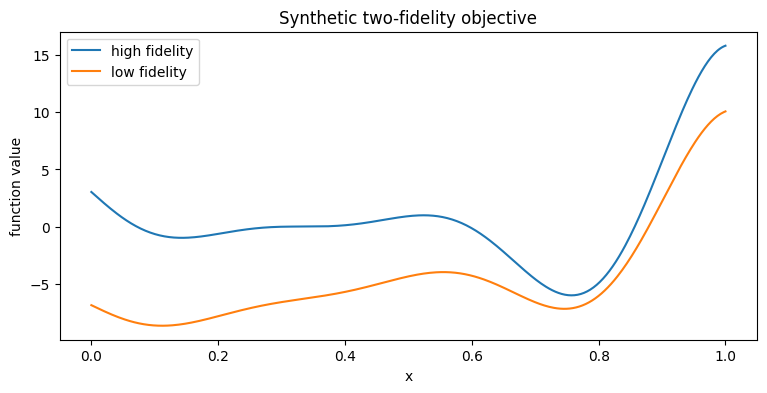

True HF optimum approx at x = 1.0000, f_H(x) = 15.8297
True LF optimum approx at x = 1.0000, f_L(x) = 10.0808


In [2]:

# Synthetic example: a classical low/high-fidelity pair on [0,1]

def f_high(x):
    x = np.asarray(x)
    return ((6*x - 2)**2) * np.sin(12*x - 4)

# A biased but correlated low-fidelity surrogate
# You can modify this to make the fidelity gap larger or smaller (try and see)
def f_low(x):
    x = np.asarray(x)
    return 0.7 * f_high(x) + 8*(x - 0.5) - 5

# Observation noise levels
noise_L = 0.15
noise_H = 0.05

# Evaluation costs
cost_L = 1.0
cost_H = 8.0

xs = np.linspace(0, 1, 400)
plt.figure(figsize=(9, 4))
plt.plot(xs, f_high(xs), label='high fidelity')
plt.plot(xs, f_low(xs), label='low fidelity')
plt.title('Synthetic two-fidelity objective')
plt.xlabel('x')
plt.ylabel('function value')
plt.legend()
plt.show()

x_star_true = xs[np.argmax(f_high(xs))]
y_star_true = np.max(f_high(xs))
print(f"True HF optimum approx at x = {x_star_true:.4f}, f_H(x) = {y_star_true:.4f}")

x_star_lf = xs[np.argmax(f_low(xs))]
y_star_lf = np.max(f_low(xs))
print(f"True LF optimum approx at x = {x_star_lf:.4f}, f_L(x) = {y_star_lf:.4f}")



# 4. GP from scratch

We now implement a small GP regression class ourselves.

We use the squared exponential / RBF kernel

$
 k(x,x') = \sigma_f^2 \exp\left(-\frac{(x-x')^2}{2\ell^2}\right).
$

The log marginal likelihood for observations $y\in\mathbb R^n$ is

$
\log p(y\mid X,\theta) =
-\frac12 y^\top K_\theta^{-1} y
-\frac12 \log |K_\theta|
-\frac n2 \log(2\pi),
$

where

$
K_\theta = K(X,X) + \sigma_n^2 I.
$

We maximize this with respect to the hyperparameters $\theta = (\ell, \sigma_f, \sigma_n)$.


In [3]:

def ensure_2d(X):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]
    return X


def rbf_kernel(X1, X2, lengthscale, variance):
    X1 = ensure_2d(X1)
    X2 = ensure_2d(X2)
    sqdist = np.sum((X1[:, None, :] - X2[None, :, :])**2, axis=-1)
    return variance * np.exp(-0.5 * sqdist / (lengthscale**2 + 1e-16))


class SimpleGP:
    def __init__(self):
        self.is_fit = False

    def _neg_log_marginal_likelihood(self, log_params):
        lengthscale = np.exp(log_params[0])
        variance = np.exp(log_params[1])
        noise = np.exp(log_params[2])

        K = rbf_kernel(self.X_train, self.X_train, lengthscale, variance)
        K = K + (noise**2 + 1e-8) * np.eye(len(self.X_train))

        try:
            c, lower = cho_factor(K, lower=True, check_finite=False)
            alpha = cho_solve((c, lower), self.y_train, check_finite=False)
            logdet = 2.0 * np.sum(np.log(np.diag(c)))
        except np.linalg.LinAlgError:
            return 1e12

        n = len(self.y_train)
        nll = 0.5 * self.y_train @ alpha + 0.5 * logdet + 0.5 * n * np.log(2*np.pi)
        return float(nll)

    def fit(self, X_train, y_train, init_log_params=None):
        self.X_train = ensure_2d(X_train)
        self.y_train = np.asarray(y_train, dtype=float).reshape(-1)

        if init_log_params is None:
            init_log_params = np.log([0.2, 1.0, 0.1])

        bounds = [(-5, 2), (-5, 5), (-8, 1)]
        res = minimize(self._neg_log_marginal_likelihood, init_log_params, method='L-BFGS-B', bounds=bounds)

        self.log_params_ = res.x
        self.lengthscale_ = np.exp(res.x[0])
        self.variance_ = np.exp(res.x[1])
        self.noise_ = np.exp(res.x[2])

        K = rbf_kernel(self.X_train, self.X_train, self.lengthscale_, self.variance_)
        K = K + (self.noise_**2 + 1e-8) * np.eye(len(self.X_train))
        self.cho_ = cho_factor(K, lower=True, check_finite=False)
        self.alpha_ = cho_solve(self.cho_, self.y_train, check_finite=False)
        self.is_fit = True
        return self

    def predict(self, X_test, return_cov=False):
        assert self.is_fit
        X_test = ensure_2d(X_test)
        K_s = rbf_kernel(self.X_train, X_test, self.lengthscale_, self.variance_)
        K_ss = rbf_kernel(X_test, X_test, self.lengthscale_, self.variance_)

        mu = K_s.T @ self.alpha_

        v = cho_solve(self.cho_, K_s, check_finite=False)
        cov = K_ss - K_s.T @ v
        cov = 0.5 * (cov + cov.T)
        var = np.clip(np.diag(cov), 1e-12, None)

        if return_cov:
            return mu, cov
        return mu, var



# 5. Single-fidelity BO warm-up

Before doing MFBO, it is useful to see the single-fidelity GP + EI workflow.


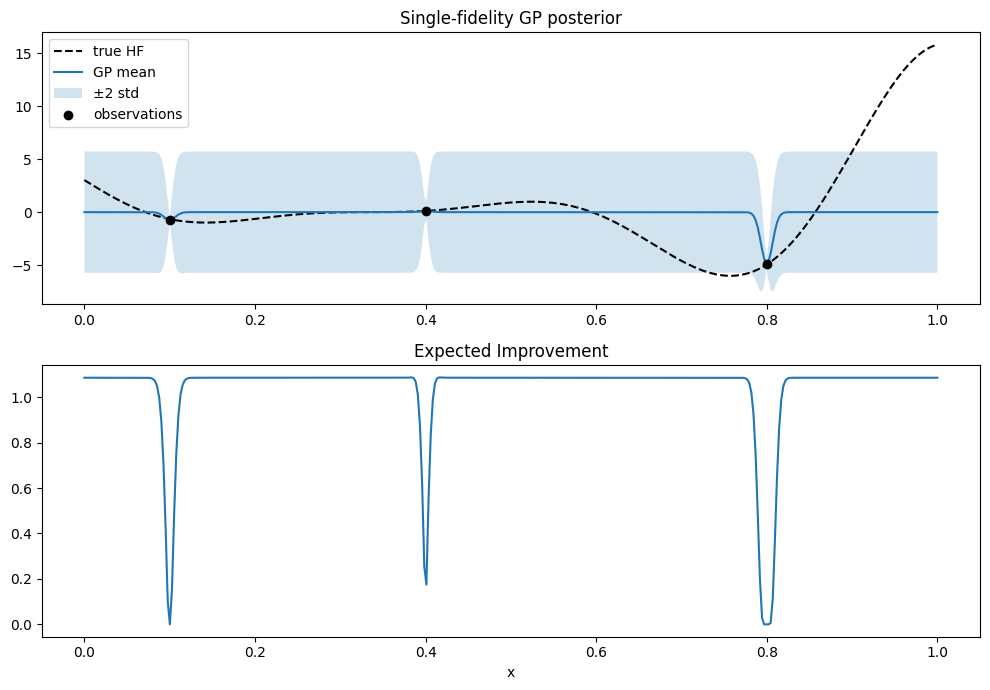

In [4]:

def expected_improvement(mu, sigma, best):
    mu = np.asarray(mu)
    sigma = np.asarray(sigma)
    out = np.zeros_like(mu)
    mask = sigma > 1e-12
    z = (mu[mask] - best) / sigma[mask]
    out[mask] = (mu[mask] - best) * norm.cdf(z) + sigma[mask] * norm.pdf(z)
    return out

# Small warm-up dataset using only high-fidelity observations
X0 = np.array([[0.1], [0.4], [0.8]])
y0 = f_high(X0[:, 0]) + rng.normal(0, noise_H, size=len(X0))

gp_sf = SimpleGP().fit(X0, y0)
mu_sf, var_sf = gp_sf.predict(xs[:, None])
std_sf = np.sqrt(var_sf)
ei_sf = expected_improvement(mu_sf, std_sf, best=np.max(y0))

plt.figure(figsize=(10, 7))
plt.subplot(2, 1, 1)
plt.plot(xs, f_high(xs), 'k--', label='true HF')
plt.plot(xs, mu_sf, label='GP mean')
plt.fill_between(xs, mu_sf - 2*std_sf, mu_sf + 2*std_sf, alpha=0.2, label='±2 std')
plt.scatter(X0[:, 0], y0, c='k', zorder=5, label='observations')
plt.legend()
plt.title('Single-fidelity GP posterior')

plt.subplot(2, 1, 2)
plt.plot(xs, ei_sf)
plt.title('Expected Improvement')
plt.xlabel('x')
plt.tight_layout()
plt.show()



# 6. Two-fidelity model from scratch

We now implement the modular AR(1) construction.

## 6.1 Model equations

We assume

$
 f_H(x) = \rho f_L(x) + \delta(x),
$

with independent GPs for $f_L$ and $\delta$.

Given LF observations, we fit a GP and obtain

$
 f_L(x) \mid \mathcal D_L \approx \mathcal N(\mu_L(x), \sigma_L^2(x)).
$

Then we estimate $\rho$ by regressing HF outputs against LF posterior means at the HF inputs:

$
 \hat\rho = \arg\min_\rho \sum_i \left(y_H(x_i^H) - \rho \mu_L(x_i^H)\right)^2.
$

For fixed $\rho$, the least-squares solution is

$
 \hat\rho = \frac{\sum_i \mu_L(x_i^H) y_H(x_i^H)}{\sum_i \mu_L(x_i^H)^2}.
$

Define residuals

$
 r_i = y_H(x_i^H) - \hat\rho \mu_L(x_i^H),
$

and fit a second GP to $(x_i^H, r_i)$.

Finally,

$
 \mu_H(x) = \hat\rho \mu_L(x) + \mu_\delta(x),
$

$
 \sigma_H^2(x) \approx \hat\rho^2 \sigma_L^2(x) + \sigma_\delta^2(x).
$

Again, please note this example is intentional kept sample for illustration purposes.


In [5]:

class TwoFidelityAR1:
    def __init__(self):
        self.gp_L = None
        self.gp_delta = None
        self.rho_ = None

    def fit(self, X_L, y_L, X_H, y_H):
        X_L = ensure_2d(X_L)
        X_H = ensure_2d(X_H)
        y_L = np.asarray(y_L).reshape(-1)
        y_H = np.asarray(y_H).reshape(-1)

        self.X_L, self.y_L = X_L, y_L
        self.X_H, self.y_H = X_H, y_H

        # Fit LF model
        self.gp_L = SimpleGP().fit(X_L, y_L)
        mu_L_at_H, var_L_at_H = self.gp_L.predict(X_H)

        denom = np.sum(mu_L_at_H**2) + 1e-12
        self.rho_ = float(np.sum(mu_L_at_H * y_H) / denom)

        residuals = y_H - self.rho_ * mu_L_at_H
        self.gp_delta = SimpleGP().fit(X_H, residuals)
        return self

    def predict_low(self, X):
        mu, var = self.gp_L.predict(X)
        return mu, var

    def predict_high(self, X):
        mu_L, var_L = self.gp_L.predict(X)
        mu_d, var_d = self.gp_delta.predict(X)
        mu_H = self.rho_ * mu_L + mu_d
        var_H = np.clip((self.rho_**2) * var_L + var_d, 1e-12, None)
        return mu_H, var_H

    def copy_and_add(self, x_new, fidelity, y_new):
        X_L = self.X_L.copy()
        y_L = self.y_L.copy()
        X_H = self.X_H.copy()
        y_H = self.y_H.copy()

        if fidelity == 'L':
            X_L = np.vstack([X_L, ensure_2d([x_new])])
            y_L = np.append(y_L, y_new)
        elif fidelity == 'H':
            X_H = np.vstack([X_H, ensure_2d([x_new])])
            y_H = np.append(y_H, y_new)
        else:
            raise ValueError("fidelity must be 'L' or 'H'")

        new_model = TwoFidelityAR1().fit(X_L, y_L, X_H, y_H)
        return new_model


Estimated rho = 6.281


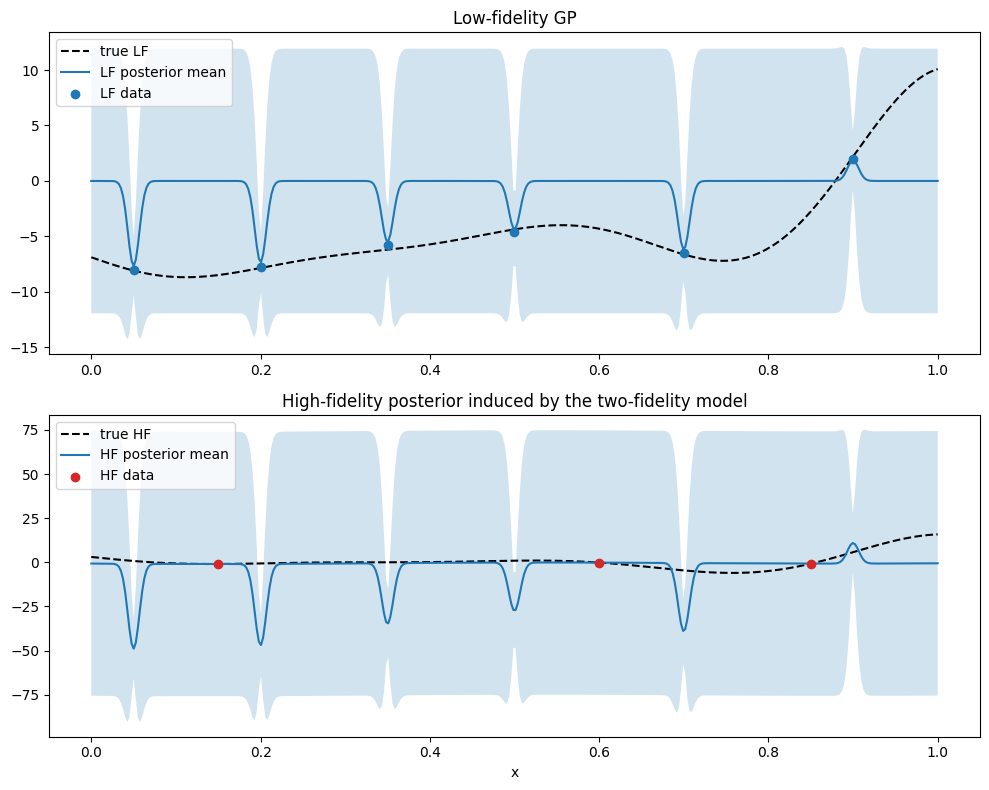

In [6]:

# Initial data: many methods start with a few LF points and very few HF points
X_L = np.array([[0.05], [0.2], [0.35], [0.5], [0.7], [0.9]])
y_L = f_low(X_L[:, 0]) + rng.normal(0, noise_L, size=len(X_L))

X_H = np.array([[0.15], [0.6], [0.85]])
y_H = f_high(X_H[:, 0]) + rng.normal(0, noise_H, size=len(X_H))

mf_model = TwoFidelityAR1().fit(X_L, y_L, X_H, y_H)
print(f"Estimated rho = {mf_model.rho_:.3f}")

mu_L, var_L = mf_model.predict_low(xs[:, None])
mu_H, var_H = mf_model.predict_high(xs[:, None])
std_L = np.sqrt(var_L)
std_H = np.sqrt(var_H)

plt.figure(figsize=(10, 8))
plt.subplot(2, 1, 1)
plt.plot(xs, f_low(xs), 'k--', label='true LF')
plt.plot(xs, mu_L, label='LF posterior mean')
plt.fill_between(xs, mu_L - 2*std_L, mu_L + 2*std_L, alpha=0.2)
plt.scatter(X_L[:, 0], y_L, c='tab:blue', zorder=5, label='LF data')
plt.legend()
plt.title('Low-fidelity GP')

plt.subplot(2, 1, 2)
plt.plot(xs, f_high(xs), 'k--', label='true HF')
plt.plot(xs, mu_H, label='HF posterior mean')
plt.fill_between(xs, mu_H - 2*std_H, mu_H + 2*std_H, alpha=0.2)
plt.scatter(X_H[:, 0], y_H, c='tab:red', zorder=5, label='HF data')
plt.legend()
plt.title('High-fidelity posterior induced by the two-fidelity model')
plt.xlabel('x')
plt.tight_layout()
plt.show()



# 7. How do we choose the next fidelity?

This is where MFBO becomes conceptually different from ordinary BO.

At each step, we must choose between:
- **an HF query**: expensive but directly informative about the target,
- **an LF query**: cheap, indirect, but can still improve the HF posterior.

---

## 7.1 An acquisition rule

A principled MFBO method would define a value-of-information objective over both $x$ and fidelity. Examples include knowledge-gradient style methods.

For learning (for now), we use a transparent approximation.

### High-fidelity score

For HF, use expected improvement on the HF surrogate:

$
 a_H(x) = \frac{\text{EI}_H(x)}{c_H}.
$

### Low-fidelity score

A low-fidelity evaluation does not directly update the objective value, so instead we ask:

> If I add a low-fidelity observation at $x$, how much would the **HF posterior variance** shrink?

Define the utility as the expected reduction of integrated HF variance:

$
 a_L(x) = \frac{1}{c_L} \cdot
\frac{1}{|\mathcal G|} \sum_{z \in \mathcal G}
\left[
\sigma_H^2(z) - \sigma_{H,\text{after LF at }x}^2(z)
\right].
$

This is a clean way to capture the idea that LF is mainly useful when it cheaply improves the HF surrogate.

---

## 7.2 Why this makes sense

- If LF is strongly correlated with HF, a cheap LF point can produce a large HF uncertainty reduction.
- If the model already knows LF very well near $x$, an extra LF sample gives little value.
- If the HF optimum region is still very uncertain, HF EI may dominate.

This is not the only valid MFBO rule, but it illustrates the tradeoff very clearly.


In [7]:

def integrated_hf_variance(model, grid):
    _, var = model.predict_high(grid)
    return float(np.mean(var))


def score_low_fidelity_by_variance_reduction(model, candidate_x, grid, hallucinated_noise=0.0):
    """
    Approximate value of an LF query at candidate_x by integrated HF variance reduction.
    We 'hallucinate' the observation using the current LF posterior mean.
    For a GP with fixed hyperparameters, posterior covariance does not depend on the observed y value,
    so using the mean is sufficient for this didactic calculation.
    """
    current_iv = integrated_hf_variance(model, grid)
    mu_L_x, _ = model.predict_low([[candidate_x]])
    new_model = model.copy_and_add(candidate_x, 'L', float(mu_L_x[0] + hallucinated_noise))
    new_iv = integrated_hf_variance(new_model, grid)
    return (current_iv - new_iv) / cost_L


def score_high_fidelity_by_ei(model, candidate_x, best_hf):
    mu_H_x, var_H_x = model.predict_high([[candidate_x]])
    ei = expected_improvement(mu_H_x, np.sqrt(var_H_x), best_hf)[0]
    return ei / cost_H


def choose_next_query(model, candidate_grid, integration_grid):
    best_hf = np.max(model.y_H)

    scores_H = np.array([score_high_fidelity_by_ei(model, x, best_hf) for x in candidate_grid])
    scores_L = np.array([score_low_fidelity_by_variance_reduction(model, x, integration_grid) for x in candidate_grid])

    iH = int(np.argmax(scores_H))
    iL = int(np.argmax(scores_L))

    if scores_H[iH] >= scores_L[iL]:
        return {'fidelity': 'H', 'x': float(candidate_grid[iH]), 'score': float(scores_H[iH]),
                'scores_H': scores_H, 'scores_L': scores_L}
    return {'fidelity': 'L', 'x': float(candidate_grid[iL]), 'score': float(scores_L[iL]),
            'scores_H': scores_H, 'scores_L': scores_L}



# 8. MFBO loop from scratch

Below, we run a simple MFBO loop.

At each iteration:
1. fit the two-fidelity surrogate,
2. score candidate LF and HF queries,
3. pick the better one after cost normalization,
4. evaluate the chosen fidelity,
5. update the data.

We track:
- the cumulative cost,
- the best observed HF value,
- where the algorithm spends LF vs HF budget.


In [8]:

# Restart with fresh initial data so the loop is reproducible
rng = np.random.default_rng(7)
X_L = np.array([[0.05], [0.2], [0.35], [0.5], [0.7], [0.9]])
y_L = f_low(X_L[:, 0]) + rng.normal(0, noise_L, size=len(X_L))

X_H = np.array([[0.15], [0.6], [0.85]])
y_H = f_high(X_H[:, 0]) + rng.normal(0, noise_H, size=len(X_H))

candidate_grid = np.linspace(0.0, 1.0, 120)
integration_grid = np.linspace(0.0, 1.0, 180)[:, None]

history = []
num_steps = 12
cumulative_cost = len(X_L) * cost_L + len(X_H) * cost_H

for step in range(num_steps):
    model = TwoFidelityAR1().fit(X_L, y_L, X_H, y_H)
    decision = choose_next_query(model, candidate_grid, integration_grid)
    x_new = decision['x']
    fidelity = decision['fidelity']

    if fidelity == 'L':
        y_new = f_low(x_new) + rng.normal(0, noise_L)
        X_L = np.vstack([X_L, [[x_new]]])
        y_L = np.append(y_L, y_new)
        cumulative_cost += cost_L
    else:
        y_new = f_high(x_new) + rng.normal(0, noise_H)
        X_H = np.vstack([X_H, [[x_new]]])
        y_H = np.append(y_H, y_new)
        cumulative_cost += cost_H

    history.append({
        'step': step + 1,
        'fidelity': fidelity,
        'x': x_new,
        'y': float(y_new),
        'best_hf_so_far': float(np.max(y_H)),
        'cumulative_cost': float(cumulative_cost),
    })

history[:3], history[-3:]


([{'step': 1,
   'fidelity': 'L',
   'x': 0.9243697478991596,
   'y': 4.673218153950214,
   'best_hf_so_far': -0.082427044896876,
   'cumulative_cost': 31.0},
  {'step': 2,
   'fidelity': 'L',
   'x': 0.4789915966386554,
   'y': -4.568302301370996,
   'best_hf_so_far': -0.082427044896876,
   'cumulative_cost': 32.0},
  {'step': 3,
   'fidelity': 'H',
   'x': 1.0,
   'y': 15.847576296382112,
   'best_hf_so_far': 15.847576296382112,
   'cumulative_cost': 40.0}],
 [{'step': 10,
   'fidelity': 'H',
   'x': 0.9915966386554621,
   'y': 15.488203031094947,
   'best_hf_so_far': 15.847576296382112,
   'cumulative_cost': 54.0},
  {'step': 11,
   'fidelity': 'H',
   'x': 1.0,
   'y': 15.76525505898486,
   'best_hf_so_far': 15.847576296382112,
   'cumulative_cost': 62.0},
  {'step': 12,
   'fidelity': 'H',
   'x': 1.0,
   'y': 15.737645194084521,
   'best_hf_so_far': 15.847576296382112,
   'cumulative_cost': 70.0}])

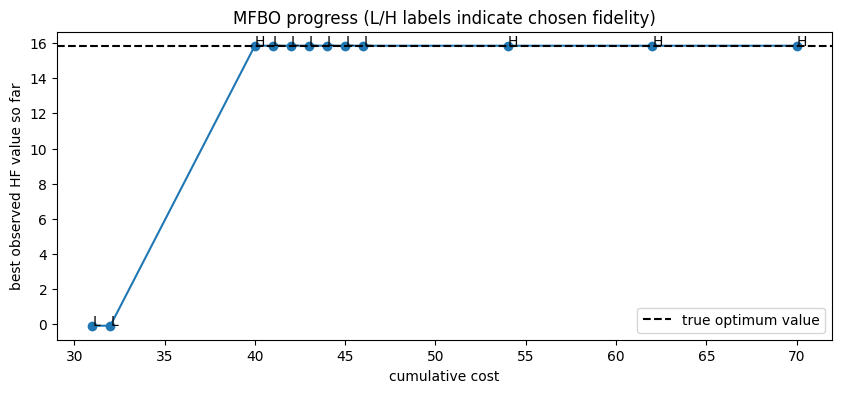

Query history:
{'step': 1, 'fidelity': 'L', 'x': 0.9243697478991596, 'y': 4.673218153950214, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 31.0}
{'step': 2, 'fidelity': 'L', 'x': 0.4789915966386554, 'y': -4.568302301370996, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 32.0}
{'step': 3, 'fidelity': 'H', 'x': 1.0, 'y': 15.847576296382112, 'best_hf_so_far': 15.847576296382112, 'cumulative_cost': 40.0}
{'step': 4, 'fidelity': 'L', 'x': 0.5042016806722689, 'y': -4.297849905106242, 'best_hf_so_far': 15.847576296382112, 'cumulative_cost': 41.0}
{'step': 5, 'fidelity': 'L', 'x': 0.7983193277310924, 'y': -6.277017232900847, 'best_hf_so_far': 15.847576296382112, 'cumulative_cost': 42.0}
{'step': 6, 'fidelity': 'L', 'x': 0.12605042016806722, 'y': -8.654861476092695, 'best_hf_so_far': 15.847576296382112, 'cumulative_cost': 43.0}
{'step': 7, 'fidelity': 'L', 'x': 0.5798319327731092, 'y': -3.9774848489051413, 'best_hf_so_far': 15.847576296382112, 'cumulative_cost': 44.0}
{'ste

In [9]:

# Visualize optimization history
steps = np.arange(1, len(history) + 1)
best_hf_so_far = np.array([h['best_hf_so_far'] for h in history])
costs = np.array([h['cumulative_cost'] for h in history])
scratch_costs_final = costs[-1]
markers = np.array([h['fidelity'] for h in history])

plt.figure(figsize=(10, 4))
plt.plot(costs, best_hf_so_far, marker='o')
for i, m in enumerate(markers):
    plt.text(costs[i], best_hf_so_far[i], m)
plt.axhline(y_star_true, color='k', linestyle='--', label='true optimum value')
plt.xlabel('cumulative cost')
plt.ylabel('best observed HF value so far')
plt.title('MFBO progress (L/H labels indicate chosen fidelity)')
plt.legend()
plt.show()

print('Query history:')
for h in history:
    print(h)


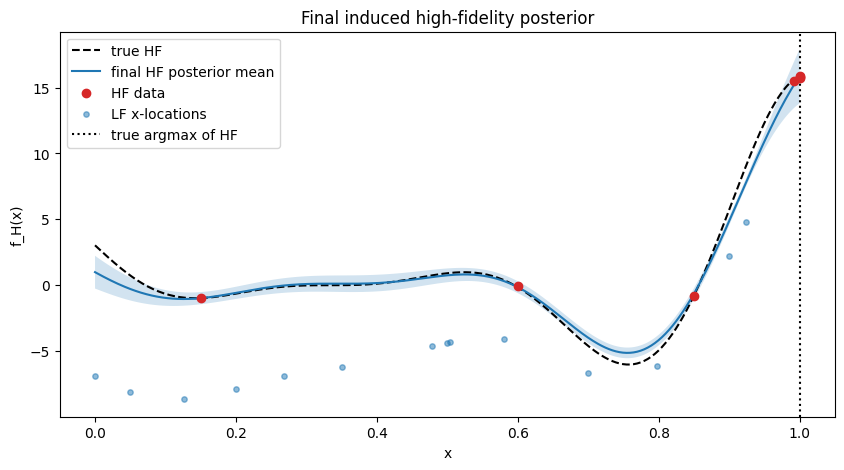

Posterior recommended x = 1.0000
True HF value at recommendation = 15.8297
Best observed HF value = 15.8476


In [10]:

# Final posterior after the loop
final_model = TwoFidelityAR1().fit(X_L, y_L, X_H, y_H)
mu_H_final, var_H_final = final_model.predict_high(xs[:, None])
std_H_final = np.sqrt(var_H_final)

plt.figure(figsize=(10, 5))
plt.plot(xs, f_high(xs), 'k--', label='true HF')
plt.plot(xs, mu_H_final, label='final HF posterior mean')
plt.fill_between(xs, mu_H_final - 2*std_H_final, mu_H_final + 2*std_H_final, alpha=0.2)
plt.scatter(X_H[:, 0], y_H, c='tab:red', zorder=5, label='HF data')
plt.scatter(X_L[:, 0], f_low(X_L[:, 0]), c='tab:blue', s=15, alpha=0.5, label='LF x-locations')
plt.axvline(x_star_true, color='k', linestyle=':', label='true argmax of HF')
plt.title('Final induced high-fidelity posterior')
plt.xlabel('x')
plt.ylabel('f_H(x)')
plt.legend()
plt.show()

x_rec = xs[np.argmax(mu_H_final)]
print(f"Posterior recommended x = {x_rec:.4f}")
print(f"True HF value at recommendation = {f_high(x_rec):.4f}")
print(f"Best observed HF value = {np.max(y_H):.4f}")



# 9. Interpreting the scratch implementation

## 9.1 What the algorithm is really doing

The loop is trying to answer two questions repeatedly:

1. **Where is the optimum of the high-fidelity function likely to be?**
2. **Should I spend budget on the expensive truth, or on a cheap correlated proxy?**

The model will usually prefer LF when:
- HF remains globally uncertain,
- LF is strongly correlated with HF,
- LF is much cheaper than HF.

It will usually prefer HF when:
- the optimum region is becoming localized,
- direct improvement on the target objective becomes more valuable,
- the LF model has mostly saturated.

---

## 9.2 What is simplified here?

Several things are simplified compared with research-grade MFBO:

1. **Modular training** instead of full joint inference.
2. **Scalar $\rho$** instead of a more flexible nonlinear cross-fidelity relationship.
3. A **didactic acquisition rule** instead of a full value-of-information objective such as MFKG.
4. A 1D benchmark with dense candidate grids.




# 10. Theoretical summary in compact notation

A compact discrete-fidelity MFBO problem can be written as

$
\max_{x \in \mathcal X} f_H(x),
$

with query set

$
\mathcal Q = \mathcal X \times \{L,H\}.
$

At step $t$, pick

$
q_t = (x_t, m_t) \in \mathcal Q,
$

observe

$
y_t = f_{m_t}(x_t) + \varepsilon_t,
$

and pay cost $c(m_t)$.

With the AR(1) model

$
f_H(x)=\rho f_L(x)+\delta(x),
$

we get the cross-covariance structure

$
\text{Cov}(f_L(x),f_L(x')) = k_L(x,x'),
$

$
\text{Cov}(f_H(x),f_L(x')) = \rho k_L(x,x'),
$

$
\text{Cov}(f_H(x),f_H(x')) = \rho^2 k_L(x,x') + k_\delta(x,x').
$

The ideal MFBO policy solves

$
q_t = \arg\max_{(x,m)} \frac{\text{value of information}(x,m)}{c(m)}.
$

The whole challenge of MFBO lies in defining and optimizing this quantity well.



# 11. Using BoTorch for MFBO

[BoTorch](https://github.com/meta-pytorch/botorch) has built-in support for multi-fidelity BO. In the current official docs, the main MFBO tutorials include:
- [**continuous multi-fidelity BO with Knowledge Gradient**](https://botorch.org/docs/tutorials/multi_fidelity_bo/),
- [**discrete multi-fidelity BO with Knowledge Gradient**](https://botorch.org/docs/tutorials/discrete_multi_fidelity_bo/).

For the fixed low/high case in this notebook, the **discrete** view is the closest conceptual match: the fidelity variable acts as a discrete information source. BoTorch also provides `SingleTaskMultiFidelityGP` as a dedicated model class in its model docs.

Below is a study-oriented example cell you can adapt in Colab. It is intentionally concise and follows the overall pattern used in the official tutorials rather than reproducing every advanced detail.


In [11]:
# In Colab, install:
!pip -q install botorch gpytorch torch

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from botorch.models.gp_regression_fidelity import SingleTaskMultiFidelityGP
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood

from botorch.acquisition import PosteriorMean
from botorch.acquisition.knowledge_gradient import qMultiFidelityKnowledgeGradient
from botorch.acquisition.cost_aware import InverseCostWeightedUtility
from botorch.models.cost import AffineFidelityCostModel
from botorch.optim import optimize_acqf

# ============================================================
# Problem setup: same as the build-from-scratch example
# ============================================================

torch.set_default_dtype(torch.double)
device = torch.device("cpu")
dtype = torch.double

rng = np.random.default_rng(7)

def f_high(x):
    x = np.asarray(x)
    return ((6 * x - 2) ** 2) * np.sin(12 * x - 4)

def f_low(x):
    x = np.asarray(x)
    return 0.7 * f_high(x) + 8 * (x - 0.5) - 5

noise_L = 0.15
noise_H = 0.05

cost_L = 1.0
cost_H = 8.0

xs = np.linspace(0.0, 1.0, 400)
y_star_true = np.max(f_high(xs))
x_star_true = xs[np.argmax(f_high(xs))]

# Initial data
X_L0 = np.array([[0.05], [0.2], [0.35], [0.5], [0.7], [0.9]])
y_L0 = f_low(X_L0[:, 0]) + rng.normal(0, noise_L, size=len(X_L0))

X_H0 = np.array([[0.15], [0.6], [0.85]])
y_H0 = f_high(X_H0[:, 0]) + rng.normal(0, noise_H, size=len(X_H0))

# ============================================================
# Utilities
# ============================================================

def build_train_tensors(X_L, y_L, X_H, y_H):
    """
    Convert separate LF/HF numpy arrays into BoTorch train_X/train_Y

    train_X has columns:
      [:, 0] = x
      [:, 1] = fidelity s
    where s=0.0 for LF and s=1.0 for HF
    """
    X_L_aug = np.hstack([X_L, np.zeros((len(X_L), 1))])
    X_H_aug = np.hstack([X_H, np.ones((len(X_H), 1))])

    train_X = np.vstack([X_L_aug, X_H_aug])
    train_Y = np.concatenate([y_L, y_H])[:, None]

    train_X_t = torch.tensor(train_X, dtype=dtype, device=device)
    train_Y_t = torch.tensor(train_Y, dtype=dtype, device=device)
    return train_X_t, train_Y_t

def fit_botorch_mf_model(X_L, y_L, X_H, y_H):
    train_X, train_Y = build_train_tensors(X_L, y_L, X_H, y_H)
    model = SingleTaskMultiFidelityGP(
        train_X=train_X,
        train_Y=train_Y,
        data_fidelities=[1],
    )
    mll = ExactMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_mll(mll)
    return model

def predict_high_posterior(model, x_grid):
    """
    Predict posterior mean/variance at target fidelity s=1.0
    """
    X = np.column_stack([x_grid, np.ones_like(x_grid)])
    X_t = torch.tensor(X, dtype=dtype, device=device)
    with torch.no_grad():
        post = model.posterior(X_t)
    mu = post.mean.squeeze(-1).cpu().numpy()
    var = post.variance.squeeze(-1).cpu().numpy()
    return mu, var

def get_current_value(model):
    """
    current_value must be the max posterior mean at target fidelity s=1.0
    """
    posterior_mean = PosteriorMean(model)
    _, current_value = optimize_acqf(
        acq_function=posterior_mean,
        bounds=torch.tensor([[0.0, 0.0],
                             [1.0, 1.0]], dtype=dtype, device=device),
        q=1,
        num_restarts=10,
        raw_samples=64,
        fixed_features={1: 1.0},
    )
    return current_value

def build_mfkg(model):
    """
    Build qMultiFidelityKnowledgeGradient for target fidelity s=1.0
    """
    current_value = get_current_value(model)

    cost_model = AffineFidelityCostModel(
        fidelity_weights={1: cost_H - cost_L},  # delta cost from s=0 to s=1
        fixed_cost=cost_L,
    )
    cost_aware_utility = InverseCostWeightedUtility(cost_model)

    def project_to_target(X):
        X_proj = X.clone()
        X_proj[..., 1] = 1.0
        return X_proj

    mfkg = qMultiFidelityKnowledgeGradient(
        model=model,
        num_fantasies=64,
        current_value=current_value,
        cost_aware_utility=cost_aware_utility,
        project=project_to_target,
    )
    return mfkg

# ============================================================
# Continuous-fidelity suggestion
# ============================================================

def choose_next_query_continuous(model):
    """
    Optimize over x in [0,1], s in [0,1].
    Returns x_new, s_new, fidelity_label, acq_value.
    """
    mfkg = build_mfkg(model)

    candidate, acq_value = optimize_acqf(
        acq_function=mfkg,
        bounds=torch.tensor([[0.0, 0.0],
                             [1.0, 1.0]], dtype=dtype, device=device),
        q=1,
        num_restarts=10,
        raw_samples=128,
    )

    x_new = float(candidate[0, 0].item())
    s_new = float(candidate[0, 1].item())

    # For actual evaluation, map to the nearest legal fidelity
    fidelity = "H" if s_new > 0.5 else "L"

    return {
        "x": x_new,
        "s_cont": s_new,
        "fidelity": fidelity,
        "acq_value": float(acq_value.item()),
    }

# ============================================================
# Discrete-fidelity suggestion
# ============================================================

def choose_next_query_discrete(model):
    """
    Restrict fidelity to {0.0, 1.0} by optimizing twice and comparing
    """
    mfkg = build_mfkg(model)

    results = []
    for s_val, label in [(0.0, "L"), (1.0, "H")]:
        candidate, acq_value = optimize_acqf(
            acq_function=mfkg,
            bounds=torch.tensor([[0.0, 0.0],
                                 [1.0, 1.0]], dtype=dtype, device=device),
            q=1,
            num_restarts=10,
            raw_samples=128,
            fixed_features={1: s_val},
        )
        results.append((candidate, acq_value, s_val, label))

    best_candidate, best_acq, best_s, best_label = max(
        results, key=lambda t: t[1].item()
    )

    return {
        "x": float(best_candidate[0, 0].item()),
        "s_cont": float(best_s),
        "fidelity": best_label,
        "acq_value": float(best_acq.item()),
        "all_results": [
            {
                "label": label,
                "x": float(cand[0, 0].item()),
                "acq_value": float(val.item()),
            }
            for cand, val, _, label in results
        ],
    }

# ============================================================
# Generic loop runner
# ============================================================

def run_botorch_mfbo_loop(mode="continuous", num_steps=200, seed=7, budget = 200):
    rng = np.random.default_rng(seed)

    X_L = X_L0.copy()
    y_L = f_low(X_L[:, 0]) + rng.normal(0, noise_L, size=len(X_L))

    X_H = X_H0.copy()
    y_H = f_high(X_H[:, 0]) + rng.normal(0, noise_H, size=len(X_H))

    history = []
    cumulative_cost = len(X_L) * cost_L + len(X_H) * cost_H
    step = 0

    while step < num_steps:
        if cumulative_cost + min(cost_L, cost_H) > budget:
            break
      # for step in range(num_steps):
        model = fit_botorch_mf_model(X_L, y_L, X_H, y_H)

        if mode == "continuous":
            decision = choose_next_query_continuous(model)
        elif mode == "discrete":
            decision = choose_next_query_discrete(model)
        else:
            raise ValueError("mode must be 'continuous' or 'discrete'")

        x_new = decision["x"]
        fidelity = decision["fidelity"]
        s_cont = decision["s_cont"]

        if fidelity == "L":
            y_new = f_low(x_new) + rng.normal(0, noise_L)
            X_L = np.vstack([X_L, [[x_new]]])
            y_L = np.append(y_L, y_new)
            cumulative_cost += cost_L
        else:
            y_new = f_high(x_new) + rng.normal(0, noise_H)
            X_H = np.vstack([X_H, [[x_new]]])
            y_H = np.append(y_H, y_new)
            cumulative_cost += cost_H

        step += 1
        history.append({
            "step": step,
            "mode": mode,
            "fidelity": fidelity,
            "x": float(x_new),
            "s_cont": float(s_cont),
            "y": float(y_new),
            "best_hf_so_far": float(np.max(y_H)),
            "cumulative_cost": float(cumulative_cost),
            "acq_value": float(decision["acq_value"]),
        })

    final_model = fit_botorch_mf_model(X_L, y_L, X_H, y_H)
    mu_H_final, var_H_final = predict_high_posterior(final_model, xs)
    std_H_final = np.sqrt(np.maximum(var_H_final, 1e-12))

    x_rec = float(xs[np.argmax(mu_H_final)])

    return {
        "history": history,
        "X_L": X_L,
        "y_L": y_L,
        "X_H": X_H,
        "y_H": y_H,
        "final_model": final_model,
        "mu_H_final": mu_H_final,
        "std_H_final": std_H_final,
        "x_rec": x_rec,
    }

# ============================================================
# Visualization helpers
# ============================================================

def plot_history(result, title_suffix=""):
    history = result["history"]
    costs = np.array([h["cumulative_cost"] for h in history])
    best_hf_so_far = np.array([h["best_hf_so_far"] for h in history])
    markers = np.array([h["fidelity"] for h in history])

    plt.figure(figsize=(10, 4))
    plt.plot(costs, best_hf_so_far, marker="o")
    for i, m in enumerate(markers):
        plt.text(costs[i], best_hf_so_far[i], m)
    plt.axhline(y_star_true, color="k", linestyle="--", label="true optimum value")
    plt.xlabel("cumulative cost")
    plt.ylabel("best observed HF value so far")
    plt.title(f"BoTorch MFBO progress {title_suffix}")
    plt.legend()
    plt.show()

def plot_final_posterior(result, title_suffix=""):
    X_L = result["X_L"]
    X_H = result["X_H"]
    y_H = result["y_H"]
    mu_H_final = result["mu_H_final"]
    std_H_final = result["std_H_final"]

    plt.figure(figsize=(10, 5))
    plt.plot(xs, f_high(xs), "k--", label="true HF")
    plt.plot(xs, mu_H_final, label="final HF posterior mean")
    plt.fill_between(
        xs,
        mu_H_final - 2 * std_H_final,
        mu_H_final + 2 * std_H_final,
        alpha=0.2,
    )
    plt.scatter(X_H[:, 0], y_H, c="tab:red", zorder=5, label="HF data")
    plt.scatter(
        X_L[:, 0],
        f_low(X_L[:, 0]),
        c="tab:blue",
        s=15,
        alpha=0.5,
        label="LF x-locations",
    )
    plt.axvline(x_star_true, color="k", linestyle=":", label="true argmax of HF")
    plt.title(f"Final induced high-fidelity posterior {title_suffix}")
    plt.xlabel("x")
    plt.ylabel("f_H(x)")
    plt.legend()
    plt.show()

def summarize_result(result, label):
    print(f"\n=== {label} ===")
    print("First 3 history rows:")
    for row in result["history"][:3]:
        print(row)
    print("\nLast 3 history rows:")
    for row in result["history"][-3:]:
        print(row)

    x_rec = result["x_rec"]
    print(f"\nPosterior recommended x = {x_rec:.4f}")
    print(f"True HF value at recommendation = {f_high(x_rec):.4f}")
    print(f"Best observed HF value = {np.max(result['y_H']):.4f}")


=== BoTorch continuous-fidelity ===
First 3 history rows:
{'step': 1, 'mode': 'continuous', 'fidelity': 'L', 'x': 1.0, 's_cont': 0.0, 'y': 9.987741127208885, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 31.0, 'acq_value': 0.057709926968739556}
{'step': 2, 'mode': 'continuous', 'fidelity': 'L', 'x': 0.0, 's_cont': 0.0, 'y': -6.807476705610022, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 32.0, 'acq_value': -0.4564842194077676}
{'step': 3, 'mode': 'continuous', 'fidelity': 'L', 'x': 0.0, 's_cont': 0.0, 'y': -6.827419961913793, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 33.0, 'acq_value': -0.4316329993764549}

Last 3 history rows:
{'step': 10, 'mode': 'continuous', 'fidelity': 'L', 'x': 0.016551242735232584, 's_cont': 0.0, 'y': -7.602712217827957, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 40.0, 'acq_value': 3.3761317751179742e-06}
{'step': 11, 'mode': 'continuous', 'fidelity': 'L', 'x': 0.4570087131651283, 's_cont': 0.0, 'y': -5.153359

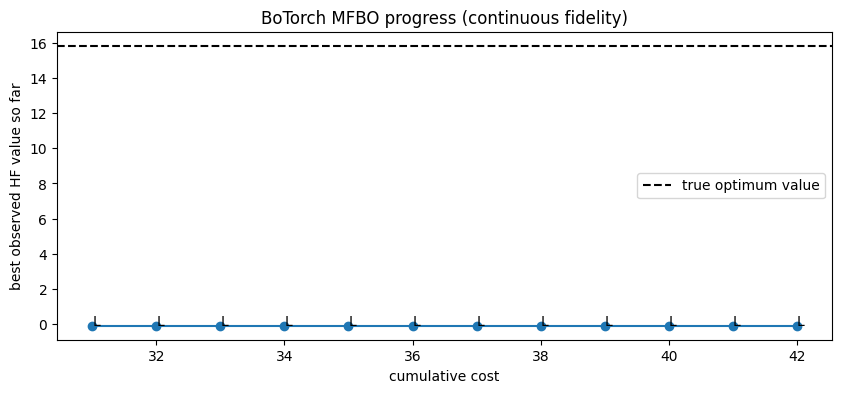

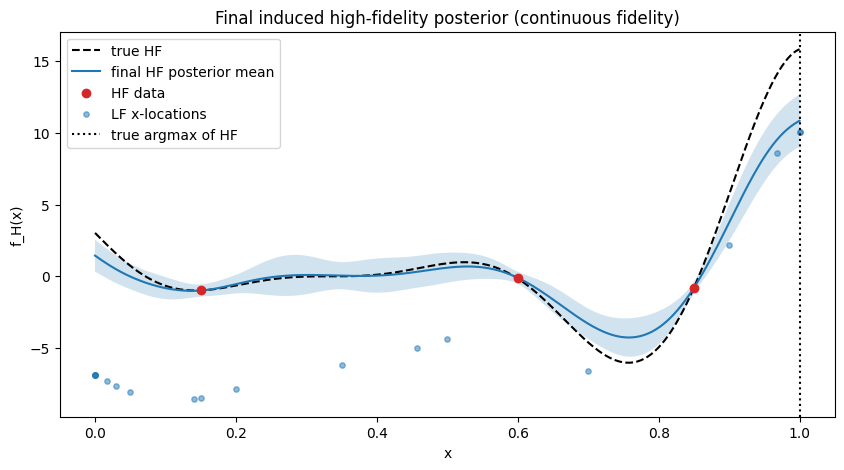


=== BoTorch discrete-fidelity ===
First 3 history rows:
{'step': 1, 'mode': 'discrete', 'fidelity': 'L', 'x': 1.0, 's_cont': 0.0, 'y': 9.987741127208885, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 31.0, 'acq_value': 0.1364661570736928}
{'step': 2, 'mode': 'discrete', 'fidelity': 'L', 'x': 0.5876939997346201, 's_cont': 0.0, 'y': -4.079625696291712, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 32.0, 'acq_value': -0.4483971990165291}
{'step': 3, 'mode': 'discrete', 'fidelity': 'L', 'x': 0.0, 's_cont': 0.0, 'y': -6.827419961913793, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 33.0, 'acq_value': -0.4391360072967948}

Last 3 history rows:
{'step': 10, 'mode': 'discrete', 'fidelity': 'L', 'x': 0.0, 's_cont': 0.0, 'y': -7.166136424107928, 'best_hf_so_far': 3.0324806936816078, 'cumulative_cost': 47.0, 'acq_value': -0.6478590826486553}
{'step': 11, 'mode': 'discrete', 'fidelity': 'L', 'x': 0.13462694538366635, 's_cont': 0.0, 'y': -8.799810870713442, 'best_h

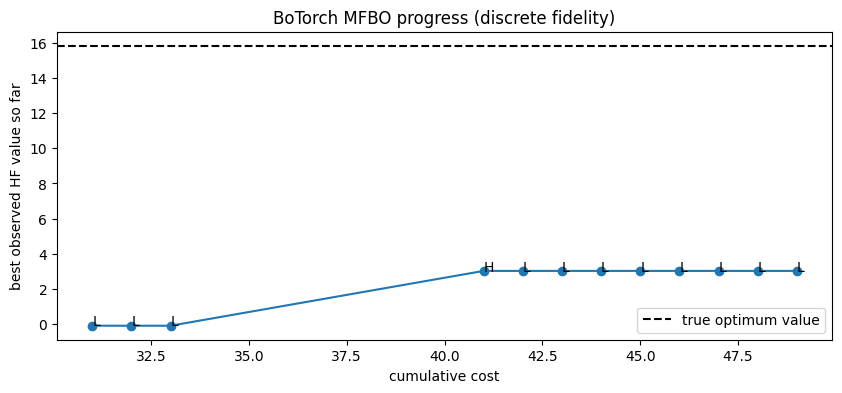

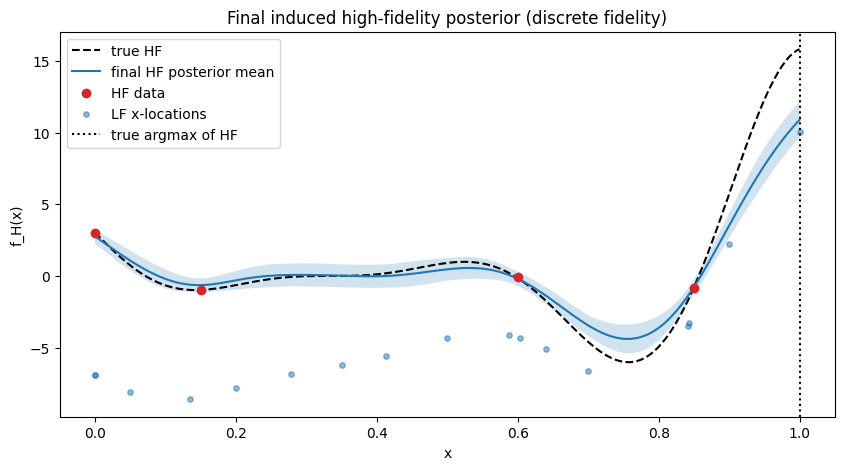

In [13]:
# ============================================================
# Run both versions (first with same number of steps)
# ============================================================

continuous_result = run_botorch_mfbo_loop(mode="continuous", num_steps=12, seed=7)
discrete_result = run_botorch_mfbo_loop(mode="discrete", num_steps=12, seed=7)

summarize_result(continuous_result, "BoTorch continuous-fidelity")
plot_history(continuous_result, "(continuous fidelity)")
plot_final_posterior(continuous_result, "(continuous fidelity)")

summarize_result(discrete_result, "BoTorch discrete-fidelity")
plot_history(discrete_result, "(discrete fidelity)")
plot_final_posterior(discrete_result, "(discrete fidelity)")

In [14]:
print(scratch_costs_final)

70.0



=== BoTorch continuous-fidelity ===
First 3 history rows:
{'step': 1, 'mode': 'continuous', 'fidelity': 'L', 'x': 1.0, 's_cont': 0.0, 'y': 9.987741127208885, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 31.0, 'acq_value': -0.1358843795732686}
{'step': 2, 'mode': 'continuous', 'fidelity': 'L', 'x': 0.0, 's_cont': 0.0, 'y': -6.807476705610022, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 32.0, 'acq_value': -0.44687340954239696}
{'step': 3, 'mode': 'continuous', 'fidelity': 'L', 'x': 0.13847968903937274, 's_cont': 0.0, 'y': -8.52721866740814, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 33.0, 'acq_value': -0.3989078077263053}

Last 3 history rows:
{'step': 38, 'mode': 'continuous', 'fidelity': 'L', 'x': 0.15104185411255422, 's_cont': 0.0, 'y': -8.345901331288005, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 68.0, 'acq_value': -0.30992058094786235}
{'step': 39, 'mode': 'continuous', 'fidelity': 'L', 'x': 0.14799186387077223, 's_cont': 0.0, '

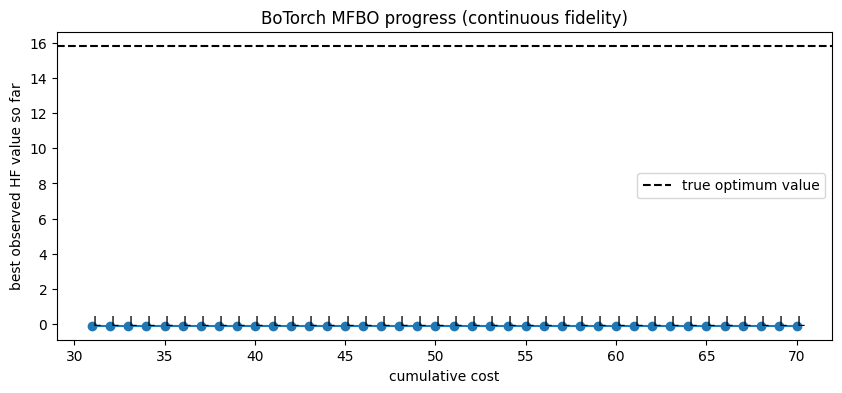

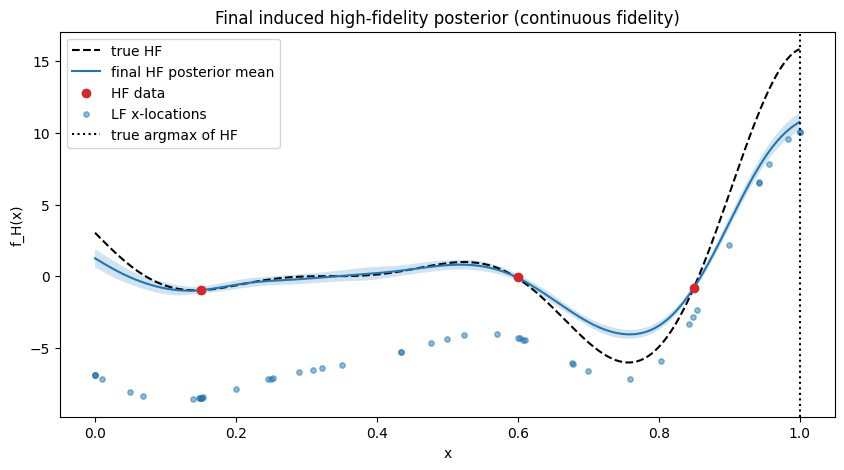


=== BoTorch discrete-fidelity ===
First 3 history rows:
{'step': 1, 'mode': 'discrete', 'fidelity': 'L', 'x': 1.0, 's_cont': 0.0, 'y': 9.987741127208885, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 31.0, 'acq_value': 0.0374502807253273}
{'step': 2, 'mode': 'discrete', 'fidelity': 'L', 'x': 0.844631317606539, 's_cont': 0.0, 'y': -3.13838606303044, 'best_hf_so_far': -0.082427044896876, 'cumulative_cost': 32.0, 'acq_value': -0.6328708384061088}
{'step': 3, 'mode': 'discrete', 'fidelity': 'H', 'x': 0.0, 's_cont': 1.0, 'y': 3.045054331639716, 'best_hf_so_far': 3.045054331639716, 'cumulative_cost': 40.0, 'acq_value': -0.21865457341981046}

Last 3 history rows:
{'step': 24, 'mode': 'discrete', 'fidelity': 'L', 'x': 0.0, 's_cont': 0.0, 'y': -7.027730874846298, 'best_hf_so_far': 3.045054331639716, 'cumulative_cost': 68.0, 'acq_value': -0.3437813147901153}
{'step': 25, 'mode': 'discrete', 'fidelity': 'L', 'x': 0.15097096410983374, 's_cont': 0.0, 'y': -8.596820309829306, 'best_hf_so

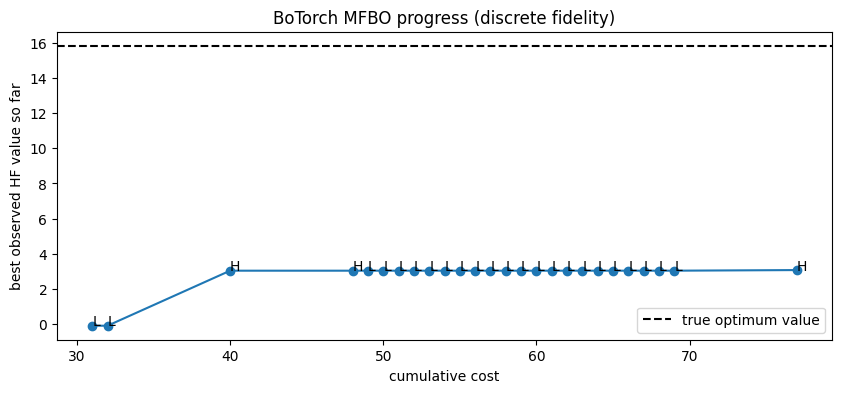

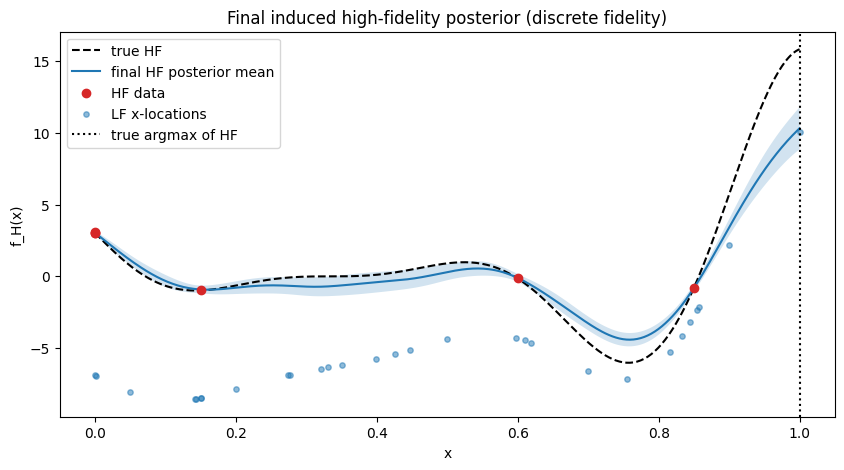

In [15]:
# ============================================================
# Run both versions (then with same buget)
# ============================================================

continuous_result = run_botorch_mfbo_loop(mode="continuous", seed=7, budget = scratch_costs_final)
discrete_result = run_botorch_mfbo_loop(mode="discrete", seed=7, budget = scratch_costs_final)

summarize_result(continuous_result, "BoTorch continuous-fidelity")
plot_history(continuous_result, "(continuous fidelity)")
plot_final_posterior(continuous_result, "(continuous fidelity)")

summarize_result(discrete_result, "BoTorch discrete-fidelity")
plot_history(discrete_result, "(discrete fidelity)")
plot_final_posterior(discrete_result, "(discrete fidelity)")

As the results show, depending on the problem, simply setting up your task in an advanced package (such as BoTorch) does not necessarily produce better results than a simple illustrative implementation. Achieving better performance often requires understanding which acquisition function to use, choosing an appropriate package, and effectively leveraging the modular features of advanced frameworks like BoTorch to design your own optimizer.

I will leave it to you to explore :)


# 12. Suggested study exercises

With the illustrative code, try these one by one.

1. **Change the LF bias**
   - Make LF more or less correlated with HF.
   - Observe when LF becomes worth querying.

2. **Change the cost ratio**
   - For example set $c_H/c_L = 3, 10, 20$.
   - How does the fidelity policy change?

3. **Increase observation noise**
   - Add more LF noise.
   - Does the model still trust cheap data?

4. **Replace the acquisition heuristic**
   - Compare EI-per-cost, UCB-per-cost, and variance-reduction-per-cost.

5. **Move to 2D**
   - Replace the 1D benchmark with a 2D synthetic function.
   - Notice how acquisition optimization becomes harder.

6. **Compare against HF-only BO**
   - Spend the same total cost budget.
   - When does MFBO beat plain BO?

7. **Try nested vs non-nested designs**
   - In some classical setups, HF points are a subset of LF points.
   - Compare that against independent LF/HF locations.


For BoTorch example, based on the knowledge gained from illustrative code by experimenting with study 1-7, try the following
1. **First, carefully read through the BoTorch documentation to become familiar with its different features and functionalities.**
2. **Then come up with a testing plan**
3. **Test out!**


# 13. Common conceptual mistakes

## Mistake 1: optimizing the low-fidelity optimum
Wrong target.

The objective is still
$
\max_x f_H(x).
$

LF is only useful insofar as it helps us learn about the HF optimum more cheaply.

## Mistake 2: treating LF as “just noisy HF”
Not necessarily.

LF can be **biased**, structurally distorted, or smoother than HF. That is why a cross-fidelity model matters.

## Mistake 3: forgetting cost
In MFBO, a mediocre but cheap information source can be very valuable.

The right question is not “which query is best?” but rather

$
\text{which query gives the best information per unit cost?}
$

## Mistake 4: over-trusting the AR(1) relationship
The AR(1) model assumes a mostly linear relationship across fidelities. If LF and HF differ in strongly nonlinear ways, the model can fail.



# 14. Final takeaway

Standard fixed-fidelity MFBO: Use a surrogate that links cheap and expensive information sources, then decide at each step which fidelity gives the best value of information per cost for optimizing the **high-fidelity** objective.

The most important mental picture is:
- HF defines the real objective,
- LF is an auxiliary information source,
- the surrogate is the bridge between them,
- the acquisition policy decides how to spend the budget.

Once that picture is clear, advanced methods such as MFKG become much easier to interpret.
